# Evidence graph updates

**Recipe 57** · Level 5 (Expert) · Decision type: `Choice` + `Noul`

Combine entity, relationship, and evidence judgments into a proposed graph update that Python validates and applies transactionally in a simulated store with replayable provenance.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S06: [TypeSafe AI: Cookbooks](https://docs.typesafe.ai/cookbooks)

## What you will build

A graph updater for a small, invented staff graph (people, organisations, and who works where). An upstream extractor proposes "this mention now works at this organisation", with a few short excerpts as evidence. Jev answers narrow questions about the proposal in two requests: a `Choice` naming which person in the graph the mention is (or `no_match`) together with a `Noul` on whether the excerpts conflict, and then, for the person it named, two `Noul` propositions on what the excerpts state about the new and the old employer. Python composes those answers into one proposed update and applies it as a transaction in a simulated store (`Store` and `Transactor` from `jev_cookbook.simulation`, [docs/simulation.md](../../docs/simulation.md)): it validates the update, checks the graph invariant on the staged writes, rolls back on failure, and logs every attempt with its provenance, so the whole graph can be rebuilt from the log.

This is a level 5 recipe: every setting is chosen on `validation` and frozen, the request budget and the seeds are printed, a keyword baseline runs under the same conditions, and `test` is read once at the end.

## Setup and run mode

The notebook runs from its own folder with the standard library and `jev_cookbook` only. `get_backend(fixtures=...)` replays stored answers offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls and changes nothing else, because the same question builders in `helpers.py` make every request in both modes. The header states which mode ran. Two labels may follow a number below. `(a pipeline check, not a Jev result)` marks a synthetic or scripted run; a recorded or live run does not print it, and its header says which mode ran. `(a selection step, not a reported result)` marks a line that is not a result to report, such as a number from `validation`, the split settings are chosen on, or a count of the items the frozen rule queues or would queue. A line with neither label, such as an individual answer or a per-example line, still comes from the mode the header names.

Every `decide()` call spends one unit of a request `Budget` first (`jev_cookbook.simulation.Budget`), created here and printed, so the limit is enforced in code: a request the budget cannot pay for is never sent, and its proposal goes to review.

In [1]:
from jev_cookbook import AuditedBackend, get_backend, load_helpers
from jev_cookbook.answers import NoulAnswer
from jev_cookbook.evaluation import accuracy, evaluate_outcomes, evaluate_threshold
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.simulation import Budget, replay_transactions
from jev_cookbook.style import apply_style, plot_answer_probabilities, run_header, show_answer

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = AuditedBackend(get_backend(fixtures=responses_path()), label="main")
# N for the header is the number of examples the metrics are about: the ones with a gold
# label, which excludes the demo examples.
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
selection = " (a selection step, not a reported result)"

# At most two requests per example (request 2 only follows request 1), for every example.
budget = Budget(requests=2 * len(examples))

run_header(
    57,
    "Evidence graph updates",
    backend=backend,
    n_examples=len(scored),
)
print(f"examples: {len(examples)} ({len(scored)} scored, {len(examples) - len(scored)} demo)")
print(f"request budget: {budget.limit('requests')} requests, enforced before every decide()")

Recipe 57: Evidence graph updates
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 24 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.
examples: 26 (24 scored, 2 demo)
request budget: 52 requests, enforced before every decide()


## The state

Python builds two states for one proposal, one per request. Each example in `fixtures/inputs.jsonl` carries `fields`: the mention, the id of the proposed organisation, and the excerpts with their sources. Request 1's state is the mention, the proposal written out in words and the excerpts; the example id and the organisation id stay in Python. The candidate people are not in the state: Python shortlists them from the graph (everyone whose surname is the mention's last word) and offers them as the options of the `Choice` below, each described by name, role and current employer. Their order comes from `jev_cookbook.fixtures.stable_permutation`, seeded per example with the key printed below, so the shown order comes neither from the data nor from the ids ([docs/fixtures.md](../../docs/fixtures.md#per-item-option-order)). That seed key is the only randomness in the recipe.

In [2]:
import json

demo = {e.id: e for e in examples if e.split == "demo"}
example = demo["d01"]
print("Python has:")
print(json.dumps(example.fields, indent=2))
state = helpers.build_first_state(example.fields)
print("Request 1, Jev sees:")
print(json.dumps(state, indent=2))
print(f"candidates Python shortlisted: {helpers.candidates(example.fields['mention'])}")
print(f"option-order seed key: {helpers.SLUG}:{example.id}")
print(f"shown order: {helpers.option_order(example.id, example.fields['mention'])}")

Python has:
{
  "mention": "P. Lund",
  "target": "O3",
  "excerpts": [
    {
      "source": "Staff newsletter",
      "text": "Survey designer P. Lund has left Halden Institute."
    },
    {
      "source": "Team blog",
      "text": "Quillmoor Analytics introduced P. Lund, who will design its customer surveys."
    }
  ]
}
Request 1, Jev sees:
{
  "mention": "P. Lund",
  "proposed_update": "P. Lund now works at Quillmoor Analytics",
  "excerpts": [
    "Staff newsletter: Survey designer P. Lund has left Halden Institute.",
    "Team blog: Quillmoor Analytics introduced P. Lund, who will design its customer surveys."
  ]
}
candidates Python shortlisted: ['P22', 'P23']
option-order seed key: 57-evidence-graph-updates:d01
shown order: ['P23', 'P22']


## The questions

Request 1 asks two independent questions about the same state, so they share one request. `entity` is a `Choice` because the mention is exactly one thing: one of the shortlisted people, or `no_match`, the fallback for a mention that is none of them (a namesake). Python builds the options from the graph, so Jev can only pick a person Python already has. `conflict` is a `Noul` written as a statement that is true or false.

Request 2 depends on request 1's answer: its state names the person `entity` chose, with that person's current employer from the graph. It asks two `Noul` propositions about that one state, one concern each, together in one request: `supported` (the excerpts state the new employment) and `ended` (the excerpts state the old one is over). Python, not Jev, turns the pair into an update: replace the employer, add one, or write nothing.

In [3]:
first_questions = helpers.build_first_questions(example.id, example.fields)
second_questions = helpers.build_second_questions()
print("Request 1:")
print(f"  entity (Choice): {first_questions['entity'].instructions}")
for name, description in first_questions["entity"].criteria.items():
    print(f"    {name:9s} {description}")
print(f"  conflict (Noul): {first_questions['conflict'].instructions}")
print("Request 2 (asked later, about the person request 1 chose):")
for name, question in second_questions.items():
    print(f"  {name} (Noul): {question.instructions}")

Request 1:
  entity (Choice): Which person in the graph is the mention in the excerpts? Read the roles and employers in the excerpts. Choose no_match when the excerpts describe a person who is none of the listed people.
    P23       Ansel Lund, microscope builder, currently works at Vantrell Clinic
    P22       Petra Lund, survey designer, currently works at Halden Institute
    no_match  None of the people listed above: the excerpts describe someone else who shares the name.
  conflict (Noul): Two of the excerpts contradict each other about where the mentioned person works now.
Request 2 (asked later, about the person request 1 chose):
  supported (Noul): The excerpts state that the person now works at the proposed employer.
  ended (Noul): The excerpts state that the person no longer works at the current employer.


## One answer up close

Request 1 for the first demo proposal, before any aggregate. The `Choice` answer holds the chosen option, a probability for every option, and a `confidence`: the top probability rescaled by the number of options, `(p_max - 1/n) / (1 - 1/n)`, 0 at an even spread and 1 when one option has all the probability ([confidence](../../docs/glossary.md#confidence)). The `Noul` answer is a single probability that the statement is true; it has no confidence field, so its threshold is chosen from examples below. The provenance line says where each answer came from.

In [4]:
budget.spend("requests")  # every decide() is paid for first
first_demo = backend.decide(state, first_questions)
show_answer(first_demo["entity"])
show_answer(first_demo["conflict"])

Choice: P22 (confidence 0.70)
  P22       0.80  ################
  no_match  0.12  ##
  P23       0.08  ##
Provenance: synthetic
Noul: 0.07 probability of yes (0 is no, 1 is yes)
Provenance: synthetic


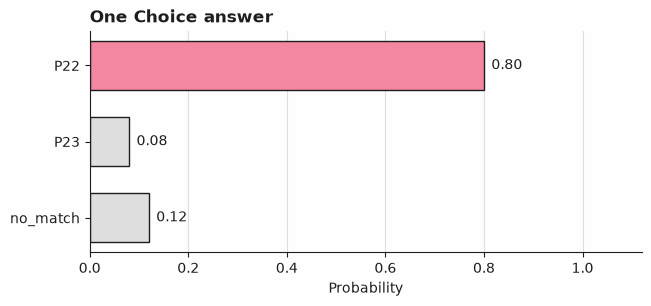

In [5]:
plot_answer_probabilities(first_demo["entity"], title="One Choice answer")

## Python's part

The rule in `helpers.py` holds whatever the model answers. `decide_first` reads request 1 and stops early in four ways: a request the budget could not pay for goes to [review](../../docs/glossary.md#review) (`request budget spent`); an `entity` answer whose confidence is below the frozen [confidence gate](../../docs/glossary.md#confidence-gate) goes to review (`confidence below the threshold`), whichever option it names, `no_match` included; a confident `no_match` writes nothing, a complete answer (link nothing) and not a deferral; and a `conflict` probability at or above its threshold goes to review (`the excerpts conflict`). Only a proposal that passes all four gets request 2. `decide` then rejects it, writing nothing, when `supported` is below its threshold, and otherwise proposes adding the new employment edge, and deleting the current one when `ended` reaches its threshold.

The settings are chosen here, on `validation`, and frozen. The gate is the lowest observed confidence at which every `validation` entity answer at or above it is right (`select_confidence_threshold(..., target_accuracy=1.0)`, through `helpers.freeze_stage_one`). Each `Noul` business threshold is the one that maximises F1 on `validation` (`select_threshold(..., "f1")`). Request 1's settings must be frozen first, because they decide which `validation` proposals get request 2.

In [6]:
val_examples = select_split(examples, "validation")
val_first = helpers.ask_first(backend, budget, val_examples)
stage_one = helpers.freeze_stage_one(
    [val_first[e.id] for e in val_examples], [labels[e.id] for e in val_examples]
)
print(f"request 1 asked for {len(val_first)} validation proposals{selection}{check}")
print(f"entity confidence gate: {stage_one.gate:.4f}{selection}{check}")
print(f"conflict threshold: {stage_one.conflict:.4f}{selection}{check}")

request 1 asked for 12 validation proposals (a selection step, not a reported result) (a pipeline check, not a Jev result)
entity confidence gate: 0.4900 (a selection step, not a reported result) (a pipeline check, not a Jev result)
conflict threshold: 0.8100 (a selection step, not a reported result) (a pipeline check, not a Jev result)


### The dependent second request

This is the request boundary. Request 2 is built from request 1's answer (the person `entity` named) and is sent only for the proposals `decide_first` lets through with request 1's frozen settings, so it is a separate, later call. Its two thresholds are chosen on the `validation` proposals that reached it with the right person matched, where the gold labels for `supported` and `ended` are about that person.

In [7]:
val_second = helpers.ask_second(backend, budget, val_examples, val_first, stage_one)
reached = [
    e
    for e in val_examples
    if e.id in val_second
    and val_first[e.id]["entity"].choice == labels[e.id]["entity"]
    and "supported" in labels[e.id]
]
settings = helpers.freeze_stage_two(
    stage_one, [val_second[e.id] for e in reached], [labels[e.id] for e in reached]
)
print(
    f"request 2 asked for {len(val_second)} of {len(val_examples)} validation proposals{selection}{check}"
)
print(f"rows the two thresholds were chosen on: {len(reached)}{selection}{check}")
print("Frozen configuration, used unchanged from here on:")
print(f"  entity confidence gate: {settings.gate:.4f} (target_accuracy=1.0){selection}{check}")
print(f"  conflict threshold: {settings.conflict:.4f} (F1 on validation){selection}{check}")
print(f"  supported threshold: {settings.supported:.4f} (F1 on validation){selection}{check}")
print(f"  ended threshold: {settings.ended:.4f} (F1 on validation){selection}{check}")
print(f"  request budget: limit {budget.limit('requests')}, used {budget.used('requests')} so far")
print(f"  seeds: option order from stable_permutation, key '{helpers.SLUG}:<example id>'")
print("  graph invariant: every edge joins live entities; one employer per person")

request 2 asked for 9 of 12 validation proposals (a selection step, not a reported result) (a pipeline check, not a Jev result)
rows the two thresholds were chosen on: 9 (a selection step, not a reported result) (a pipeline check, not a Jev result)
Frozen configuration, used unchanged from here on:
  entity confidence gate: 0.4900 (target_accuracy=1.0) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  conflict threshold: 0.8100 (F1 on validation) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  supported threshold: 0.7600 (F1 on validation) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  ended threshold: 0.4100 (F1 on validation) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  request budget: limit 52, used 22 so far
  seeds: option order from stable_permutation, key '57-evidence-graph-updates:<example id>'
  graph invariant: every edge joins live entities; o

### The rule on the two demo proposals

With every setting frozen, the rule runs on the two demo proposals. `d01` passes request 1, so it gets request 2, built from the person it named. `d02`'s `entity` confidence is below the gate, so it never gets request 2 and goes to review. `helpers.run_updates` then seeds a fresh graph with one `seed_graph` transaction and acts on each decision; a proposed update is one more transaction, with `validate_update` before the staged writes and `graph_invariant` after them.

In [8]:
demo_examples = [demo["d01"], demo["d02"]]
demo_first = {"d01": first_demo, **helpers.ask_first(backend, budget, [demo["d02"]])}
demo_second = helpers.ask_second(backend, budget, demo_examples, demo_first, settings)
print(f"request 2 sent for: {sorted(demo_second)}")
person = demo_first["d01"]["entity"].choice
print("Request 2 for d01, built from request 1's choice; Jev sees:")
print(json.dumps(helpers.build_second_state(demo["d01"].fields, person), indent=2))
for name in ("supported", "ended"):
    print(f"  {name}: ", end="")
    show_answer(demo_second["d01"][name])
decisions = [
    helpers.decide(e, demo_first[e.id], demo_second.get(e.id), settings) for e in demo_examples
]
demo_tx, demo_queue, demo_outcomes = helpers.run_updates(decisions, "rule:apply_update")
for outcome in demo_outcomes:
    print(f"{outcome.example}: {outcome.outcome} ({outcome.reason}) {list(outcome.ops)}")
record = demo_tx.log[-1].to_dict()
print(
    "d01's transaction:",
    {k: record[k] for k in ("name", "status", "rule", "ops", "version_before", "version_after")},
)
for item in demo_queue.to_dicts():
    print(f"review item {item['id']}: {item['item']['example']} -> reason: {item['reason']}")

request 2 sent for: ['d01']
Request 2 for d01, built from request 1's choice; Jev sees:
{
  "person": "Petra Lund, survey designer",
  "current_employer": "Halden Institute",
  "proposed_employer": "Quillmoor Analytics",
  "excerpts": [
    "Staff newsletter: Survey designer P. Lund has left Halden Institute.",
    "Team blog: Quillmoor Analytics introduced P. Lund, who will design its customer surveys."
  ]
}
  supported: Noul: 0.88 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
  ended: Noul: 0.84 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
d01: applied (the transaction committed) [('delete', 'edge:P22|works_at|O2'), ('put', 'edge:P22|works_at|O3')]
d02: review (confidence below the threshold) []
d01's transaction: {'name': 'works_at:d01', 'status': 'committed', 'rule': 'replace the employer', 'ops': [{'op': 'delete', 'key': 'edge:P22|works_at|O2'}, {'op': 'put', 'key': 'edge:P22|works_at|O3', 'value': {'person': 'P22', 'relation': 'works_at', 'org': 'O

## Evaluation

Every setting was frozen above, on `validation`. The headline metric is update accuracy against the [gold label](../../docs/glossary.md#gold-label): the share of proposals whose committed operations are exactly the operations the gold label says should be committed (from `fixtures/labels.jsonl`, never shown to Jev). Gold says to write nothing for a namesake, a conflict, an unsupported relationship and an update the graph cannot hold, so a proposal sent to review is right when gold writes nothing and wrong when gold has a write it missed. Beside it, `evaluate_outcomes` reports [coverage](../../docs/glossary.md#coverage) (the share not sent to review) and the accuracy and [risk](../../docs/glossary.md#risk) among those, built from what the rule actually returned rather than from a confidence alone, because the rule has review branches that are not the confidence gate ([docs/evaluation.md](../../docs/evaluation.md#selective-prediction)). Wrong writes, committed operations that gold does not have, are counted separately: they are what is left standing in the graph.

In a synthetic or scripted run every metric printed here is a check that the pipeline works, and its line says so; per-example lines are not metrics. Every `validation` number is also a selection step. Some `validation` numbers cannot come out otherwise, and the cells say which: the gate is chosen so that every `validation` entity answer at or above it is right, so the entity accuracy among gated-through `validation` answers is 1.0000 by construction of `target_accuracy=1.0`; and the `validation` conflict and `supported` probabilities of this fixture set separate gold-true from gold-false, so the F1 objective reaches 1.0000 on both (a `validation` row on the wrong side of the others would make it fall). The `ended` threshold cannot separate its `validation` rows, which is why one `validation` update is wrong.

In [9]:
def score(split_examples, outcomes):
    """Update accuracy, the outcomes view and wrong writes for one split."""
    gold = [helpers.gold_ops(labels[e.id]) for e in split_examples]
    right = [o.ops == g for o, g in zip(outcomes, gold, strict=True)]
    accepted = [o.outcome != helpers.REVIEW for o in outcomes]
    wrong_writes = sum(bool(o.ops) and o.ops != g for o, g in zip(outcomes, gold, strict=True))
    return sum(right), evaluate_outcomes(accepted, right), wrong_writes


val_decisions = [
    helpers.decide(e, val_first[e.id], val_second.get(e.id), settings) for e in val_examples
]
val_tx, val_queue, val_outcomes = helpers.run_updates(val_decisions, "rule:apply_update")
for e, o in zip(val_examples, val_outcomes, strict=True):
    ok = o.ops == helpers.gold_ops(labels[e.id])
    print(f"  {e.id:18s} {o.outcome:8s} {o.reason:48s} {'right' if ok else 'WRONG'}")
n_right, val_sel, val_wrong = score(val_examples, val_outcomes)
gated = [
    val_first[e.id]["entity"].choice == labels[e.id]["entity"]
    for e in val_examples
    if val_first[e.id]["entity"].confidence >= settings.gate
]
print(f"validation, {len(val_examples)} proposals{selection}{check}")
print(
    f"entity accuracy among gated-through answers: {sum(gated) / len(gated):.4f} (forced by target_accuracy=1.0){selection}{check}"
)
print(
    f"update accuracy: {n_right} of {len(val_examples)} = {n_right / len(val_examples):.4f}{selection}{check}"
)
print(
    f"coverage {val_sel.coverage:.4f}, accuracy {val_sel.accuracy:.4f}, risk {val_sel.risk:.4f} over {val_sel.n_answered} answered{selection}{check}"
)
print(f"wrong writes: {val_wrong}{selection}{check}")
frozen = {"conflict": settings.conflict, "supported": settings.supported, "ended": settings.ended}
noul_rows = {
    "conflict": (val_examples, val_first),
    "supported": (reached, val_second),
    "ended": (reached, val_second),
}
for name, (rows, answers) in noul_rows.items():
    point = evaluate_threshold(
        [labels[e.id][name] for e in rows], [answers[e.id][name].noul for e in rows], frozen[name]
    )
    print(f"{name} F1 at its frozen threshold, {len(rows)} rows: {point.f1:.4f}{selection}{check}")

  v01                applied  the transaction committed                        right
  v02-initial        applied  the transaction committed                        right
  v03-no-match       review   confidence below the threshold                   right
  v04-unsupported    rejected the evidence does not support the relationship   right
  v05-invariant      review   the transaction was rolled back                  right
  v06-left-only      rejected the evidence does not support the relationship   right
  v07-conflict       review   the excerpts conflict                            right
  v08                applied  the transaction committed                        right
  v09-initial        applied  the transaction committed                        right
  v10                applied  the transaction committed                        right
  v11-invariant      applied  the transaction committed                        WRONG
  v12-no-match       review   confidence below the threshold     

### The test split, read once

`test` is read here and only here, with every setting frozen. Request 1 goes out for every `test` proposal first; each answer is shown with its choice, its probabilities and its confidence before anything is counted.

In [10]:
test_examples = select_split(examples, "test")
test_first = helpers.ask_first(backend, budget, test_examples)
for e in test_examples:
    entity, conflict = test_first[e.id]["entity"], test_first[e.id]["conflict"]
    probs = ", ".join(f"{k} {v:.2f}" for k, v in entity.probabilities.items())
    print(
        f"  {e.id:18s} entity {entity.choice:8s} confidence {entity.confidence:.2f} [{probs}]  conflict {conflict.noul:.2f}"
    )

  t01                entity P12      confidence 0.85 [P12 0.90, P11 0.04, no_match 0.06]  conflict 0.06
  t02-initial        entity P07      confidence 0.61 [P07 0.74, P06 0.16, no_match 0.10]  conflict 0.11
  t03-left-only      entity P14      confidence 0.86 [P14 0.91, P13 0.03, no_match 0.06]  conflict 0.09
  t04-invariant      entity P15      confidence 0.88 [P15 0.92, P16 0.03, no_match 0.05]  conflict 0.24
  t05-unsupported    entity P10      confidence 0.83 [P10 0.89, P09 0.05, no_match 0.06]  conflict 0.07
  t06-conflict       entity P16      confidence 0.79 [P16 0.86, P15 0.05, no_match 0.09]  conflict 0.88
  t07-no-match       entity no_match confidence 0.72 [no_match 0.81, P01 0.10, P02 0.09]  conflict 0.05
  t08-wrong-match    entity P17      confidence 0.67 [P17 0.78, P18 0.15, no_match 0.07]  conflict 0.10
  t09                entity P19      confidence 0.82 [P19 0.88, P20 0.05, no_match 0.07]  conflict 0.05
  t10-missed         entity P20      confidence 0.77 [P20 0.85, 

Then request 2, the dependent one, only for the `test` proposals `decide_first` lets through.

In [11]:
test_second = helpers.ask_second(backend, budget, test_examples, test_first, settings)
print(f"request 2 sent for {len(test_second)} of {len(test_examples)} test proposals")
for e in test_examples:
    if e.id in test_second:
        s = test_second[e.id]
        print(
            f"  {e.id:18s} about {test_first[e.id]['entity'].choice}: supported {s['supported'].noul:.2f}, ended {s['ended'].noul:.2f}"
        )

request 2 sent for 9 of 12 test proposals
  t01                about P12: supported 0.88, ended 0.79
  t02-initial        about P07: supported 0.85, ended 0.90
  t03-left-only      about P14: supported 0.21, ended 0.86
  t04-invariant      about P15: supported 0.86, ended 0.19
  t05-unsupported    about P10: supported 0.78, ended 0.12
  t08-wrong-match    about P17: supported 0.81, ended 0.55
  t09                about P19: supported 0.90, ended 0.80
  t10-missed         about P20: supported 0.70, ended 0.85
  t11-conflict       about P21: supported 0.83, ended 0.66


In [12]:
test_decisions = [
    helpers.decide(e, test_first[e.id], test_second.get(e.id), settings) for e in test_examples
]
test_tx, test_queue, test_outcomes = helpers.run_updates(test_decisions, "rule:apply_update")
for e, o in zip(test_examples, test_outcomes, strict=True):
    ok = o.ops == helpers.gold_ops(labels[e.id])
    print(f"  {e.id:18s} {o.outcome:8s} {o.reason:48s} {'right' if ok else 'WRONG'} {list(o.ops)}")
n_right, test_sel, test_wrong = score(test_examples, test_outcomes)
print(f"test, {len(test_examples)} proposals, settings frozen{check}")
print(
    f"entity accuracy: {accuracy([labels[e.id]['entity'] for e in test_examples], [test_first[e.id]['entity'] for e in test_examples]):.4f}{check}"
)
print(
    f"update accuracy: {n_right} of {len(test_examples)} = {n_right / len(test_examples):.4f}{check}"
)
print(
    f"coverage {test_sel.coverage:.4f}, accuracy {test_sel.accuracy:.4f}, risk {test_sel.risk:.4f} over {test_sel.n_answered} answered{check}"
)
print(f"wrong writes: {test_wrong}{check}")
reasons = {}
for o in test_outcomes:
    if o.outcome == helpers.REVIEW:
        reasons[o.reason] = reasons.get(o.reason, 0) + 1
for reason, count in sorted(reasons.items()):
    print(f"  review because {reason}: {count}{check}")
print(f"requests used so far: {budget.used('requests')} of {budget.limit('requests')}")

  t01                applied  the transaction committed                        right [('delete', 'edge:P12|works_at|O3'), ('put', 'edge:P12|works_at|O2')]
  t02-initial        applied  the transaction committed                        right [('delete', 'edge:P07|works_at|O4'), ('put', 'edge:P07|works_at|O1')]
  t03-left-only      rejected the evidence does not support the relationship   right []
  t04-invariant      review   the transaction was rolled back                  right []
  t05-unsupported    review   the transaction was rolled back                  right []
  t06-conflict       review   the excerpts conflict                            right []
  t07-no-match       no_match the mention matches no listed person             right []
  t08-wrong-match    applied  the transaction committed                        WRONG [('delete', 'edge:P17|works_at|O1'), ('put', 'edge:P17|works_at|O2')]
  t09                applied  the transaction committed                        right [('delete'

The wrong `test` updates are the cases the rule could not catch. A confidently wrong person match (`t08-wrong-match`) passes the gate, and request 2 is then asked about the wrong person, so the excerpts' new employer is written onto a namesake's record. A missed conflict (`t11-conflict`) lets an update through that a person should have looked at. A `supported` probability below its threshold (`t10-missed`) drops a real update, which leaves the graph stale but writes nothing wrong. And the gate sends `t12-low-confidence` to review, which gold counts as a missed update. The graph invariant also caught a wrong answer: `t05-unsupported`'s `supported` probability reads a visit as a new job, and the add is rolled back because the person would then work at two organisations.

### The propositions, one at a time

Each `Noul` at its frozen threshold, on the `test` rows where its gold is defined: `conflict` on every `test` proposal, and `supported` and `ended` on the rows that reached request 2 with the right person matched (on a wrongly matched row the gold is about a different person). Because `supported` and `ended` are two propositions about one state, the fixture set carries a gold-true and a gold-false row for each in both scored splits and every truth combination of the pair in both (both true, both false, each true alone; none is excluded), counted below. For each proposition the last lines show a row where its tag alone changes the composed outcome: `t01`'s stored answers with only that one probability moved to the other side of its threshold, run through the same `decide` and `run_updates`. Two `test` numbers below sit at 1.0000 without being forced by any selection: `conflict` precision (no `test` proposal without a conflict reaches the frozen `conflict` threshold) and `ended`'s F1 (every `ended` probability on these rows falls on the gold side of its threshold). A false alarm above the `conflict` threshold, or one `ended` probability on the wrong side of its threshold, would lower them.

In [13]:
conflict_gold = [labels[e.id]["conflict"] for e in test_examples]
conflict_p = [test_first[e.id]["conflict"].noul for e in test_examples]
point = evaluate_threshold(conflict_gold, conflict_p, settings.conflict)
print(
    f"conflict on {len(test_examples)} test rows: precision {point.precision:.4f}, recall {point.recall:.4f}, F1 {point.f1:.4f}{check}"
)
asked = [
    e
    for e in test_examples
    if e.id in test_second
    and test_first[e.id]["entity"].choice == labels[e.id]["entity"]
    and "supported" in labels[e.id]
]
for name in ("supported", "ended"):
    gold = [labels[e.id][name] for e in asked]
    probs = [test_second[e.id][name].noul for e in asked]
    point = evaluate_threshold(gold, probs, frozen[name])
    print(
        f"{name} on {len(asked)} test rows: precision {point.precision:.4f}, recall {point.recall:.4f}, F1 {point.f1:.4f}{check}"
    )

for split in ("validation", "test"):
    combos = {}
    for e in select_split(examples, split):
        if "supported" in labels[e.id]:
            key = (labels[e.id]["supported"], labels[e.id]["ended"])
            combos[key] = combos.get(key, 0) + 1
    shown = ", ".join(
        f"supported={s} ended={n}: {combos.get((s, n), 0)}"
        for s in (True, False)
        for n in (True, False)
    )
    print(f"gold combinations in {split}: {shown}")

row = next(e for e in test_examples if e.id == "t01")
original = test_second["t01"]
flipped = {
    "supported": {
        "supported": NoulAnswer(0.0, original["supported"].provenance),
        "ended": original["ended"],
    },
    "ended": {
        "supported": original["supported"],
        "ended": NoulAnswer(0.0, original["ended"].provenance),
    },
}
counterfactual = [
    helpers.decide(row, test_first["t01"], flipped[name], settings)
    for name in ("supported", "ended")
]
_, _, flipped_outcomes = helpers.run_updates(counterfactual, "rule:counterfactual")
as_committed = next(o for o in test_outcomes if o.example == "t01")
print(f"t01 as committed: {as_committed.outcome} ({as_committed.reason})")
for name, o in zip(("supported", "ended"), flipped_outcomes, strict=True):
    print(f"t01 with only {name} set to 0.0: {o.outcome} ({o.reason})")

conflict on 12 test rows: precision 1.0000, recall 0.5000, F1 0.6667 (a pipeline check, not a Jev result)
supported on 7 test rows: precision 0.8000, recall 0.8000, F1 0.8000 (a pipeline check, not a Jev result)
ended on 7 test rows: precision 1.0000, recall 1.0000, F1 1.0000 (a pipeline check, not a Jev result)
gold combinations in validation: supported=True ended=True: 5, supported=True ended=False: 2, supported=False ended=True: 1, supported=False ended=False: 1
gold combinations in test: supported=True ended=True: 6, supported=True ended=False: 1, supported=False ended=True: 1, supported=False ended=False: 1
t01 as committed: applied (the transaction committed)
t01 with only supported set to 0.0: rejected (the evidence does not support the relationship)
t01 with only ended set to 0.0: review (the transaction was rolled back)


### Baseline under the same conditions

`helpers.baseline_decide` is a deterministic keyword rule over the same fields: the entity is the one candidate whose full name appears in an excerpt (otherwise `no_match`); it has no conflict check; `supported` is the proposed organisation's name appearing in an excerpt; `ended` is the current employer's name appearing together with a leaving cue (`left`, `moved from`, `retired`, ...). It sends no request, and its decisions go through the same `run_updates`: the same seed graph, the same validator, the same invariant and the same rollback. Below are its numbers on both splits and, for `test`, the proposals the two rules decide differently.

In [14]:
baseline = {}
for split, split_examples in (("validation", val_examples), ("test", test_examples)):
    label = selection if split == "validation" else ""
    decisions = [helpers.baseline_decide(e) for e in split_examples]
    _, _, outcomes = helpers.run_updates(decisions, "rule:baseline")
    baseline[split] = outcomes
    n_right, sel, wrong = score(split_examples, outcomes)
    print(
        f"baseline, {split}: update accuracy {n_right} of {len(split_examples)} = {n_right / len(split_examples):.4f}{label}{check}"
    )
    print(
        f"baseline, {split}: coverage {sel.coverage:.4f}, accuracy {sel.accuracy:.4f}, wrong writes {wrong}{label}{check}"
    )
different = [
    (e, a, b)
    for e, a, b in zip(test_examples, test_outcomes, baseline["test"], strict=True)
    if a.ops != b.ops or a.outcome != b.outcome
]
right_rule = sum(a.ops == helpers.gold_ops(labels[e.id]) for e, a, _ in different)
right_base = sum(b.ops == helpers.gold_ops(labels[e.id]) for e, _, b in different)
rollback_right = sum(
    b.reason == helpers.REASON_ROLLED_BACK and b.ops == helpers.gold_ops(labels[e.id])
    for e, b in zip(test_examples, baseline["test"], strict=True)
)
print(f"baseline right answers on test that are rolled-back updates: {rollback_right}{check}")
print(
    f"test proposals decided differently: {len(different)}; right under the rule {right_rule}, under the baseline {right_base}{check}"
)
for e, a, b in different:
    print(f"  {e.id:18s} rule {a.outcome} ({a.reason}); baseline {b.outcome} ({b.reason})")

baseline, validation: update accuracy 10 of 12 = 0.8333 (a selection step, not a reported result) (a pipeline check, not a Jev result)
baseline, validation: coverage 0.6667, accuracy 0.7500, wrong writes 0 (a selection step, not a reported result) (a pipeline check, not a Jev result)
baseline, test: update accuracy 8 of 12 = 0.6667 (a pipeline check, not a Jev result)
baseline, test: coverage 0.5833, accuracy 0.5714, wrong writes 0 (a pipeline check, not a Jev result)
baseline right answers on test that are rolled-back updates: 4 (a pipeline check, not a Jev result)
test proposals decided differently: 5; right under the rule 1, under the baseline 1 (a pipeline check, not a Jev result)
  t02-initial        rule applied (the transaction committed); baseline no_match (the mention matches no listed person)
  t08-wrong-match    rule applied (the transaction committed); baseline no_match (the mention matches no listed person)
  t10-missed         rule rejected (the evidence does not support 

On these fixtures the baseline cannot match an abbreviated or partial name (`R. Pell`, `B. Calloway`, `Calloway`), and its leaving cue misses `t10-missed`'s wording, so that replacement becomes an add the invariant refuses. Many of its right `test` answers are rolled-back updates, counted above: with no conflict check and a narrow leaving cue, it proposes adds that the graph invariant then refuses, and the invariant, not the keyword rule, keeps those rows right. It also commits no wrong write on either split, where the rule commits some: the rule's wrong writes come from a confident wrong match and a missed conflict, which a rule that writes less often avoids. Its zero wrong writes are not forced: a keyword match on the wrong person, or a leaving cue read on the wrong row, would commit one.

### Rollback test

A transaction that fails its validator or the invariant must leave the store exactly as it was. For every rolled-back entry in the `test` log, the cell checks that the store's version did not move and that the live graph before and after the attempt is the same.

In [15]:
store = test_tx.store
rolled = [r for r in test_tx.log if r.status == "rolled_back"]
for r in rolled:
    unchanged = r.version_after == r.version_before and store.at(r.version_before) == store.at(
        r.version_after
    )
    print(f"  {r.name}: {r.error}")
    print(f"    version {r.version_before} -> {r.version_after}, graph unchanged: {unchanged}")
print(
    f"rolled-back transactions: {len(rolled)} of {len(test_tx.log)} attempts, none changed the store: {all(r.version_after == r.version_before for r in rolled)}{check}"
)

  works_at:t04-invariant: ValueError: invariant rejected: ['P15 would work at 2 organisations: O1, O5']
    version 56 -> 56, graph unchanged: True
  works_at:t05-unsupported: ValueError: invariant rejected: ['P10 would work at 2 organisations: O1, O3']
    version 56 -> 56, graph unchanged: True
rolled-back transactions: 2 of 8 attempts, none changed the store: True (a pipeline check, not a Jev result)


### Replay test

`replay_transactions(tx.log)` rebuilds a fresh store from the committed entries alone. Every write in the rebuilt `test` graph, with its writer, step, rule and the answers behind it, must equal the original, so the log is the graph's provenance.

In [16]:
rebuilt = replay_transactions(test_tx.log)
print(f"committed transactions: {sum(r.committed for r in test_tx.log)} of {len(test_tx.log)}")
print(f"writes: original {store.version}, rebuilt {rebuilt.version}")
print(f"identical history and provenance: {rebuilt.to_dicts() == store.to_dicts()}")
print(f"identical final graph: {rebuilt.snapshot() == store.snapshot()}")
last = store.writes()[-1].to_dict()
print("last write:", {k: last[k] for k in ("version", "key", "writer", "step", "rule")})
print("  answers behind it:", sorted(last["answer"]))

committed transactions: 6 of 8
writes: original 62, rebuilt 62
identical history and provenance: True
identical final graph: True
last write: {'version': 62, 'key': 'edge:P21|works_at|O5', 'writer': 'rule:apply_update', 'step': 11, 'rule': 'replace the employer'}
  answers behind it: ['conflict', 'ended', 'entity', 'supported']


## What was and was not measured

Not measured live: the offline run replays synthetic answers, so its numbers check the pipeline and say nothing about how Jev performs. The cell below states the mode from `backend.mode` and N, the number of proposals the reported numbers cover. The fixture set is 26 invented proposals over an invented graph: 12 `validation`, 12 `test` and 2 `demo`, written for this recipe with stored answers that are wrong on purpose in places. Nothing here says anything about Jev's quality, speed or cost.

In [17]:
print(
    f"examples: {len(examples)}: {len(val_examples)} validation, {len(test_examples)} test, {len(demo)} demo"
)
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test proposals{check}")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test proposals")
print(f"request budget: used {budget.used('requests')} of {budget.limit('requests')}")

examples: 26: 12 validation, 12 test, 2 demo
Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 12 validation and 12 test proposals (a pipeline check, not a Jev result)
request budget: used 45 of 52


### Live request audit

The cell below is this notebook's final code cell, on purpose: `backend.audit_json()` prints an ordered ledger of every `decide()` call the backend above made. [`request_budget.json`](request_budget.json) declares this notebook's live request count once, and the recipe guard checks the ledger, the declaration and the README's rendered paragraph against each other ([docs/backends.md](../../docs/backends.md#actual-calls-and-distinct-requests)). It holds no response content and says nothing about Jev's quality, speed or cost.

In [18]:
print(backend.audit_json())

JEV_REQUEST_AUDIT {"schema":2,"backends":[{"label":"main","decide_calls":45,"distinct_requests":45,"calls":[{"replay_key":"2ea3a015eecba06df5826b8d07809067b853a2f401d957e921d4074532e844f6","returned":true},{"replay_key":"d23d4c1f99d0dfcfae1d4b908578f48ebb8f1af02662641660486d22a9bb2dee","returned":true},{"replay_key":"12bc3f96b35368e0b97007b745b2cab1814c7ad658cde57cb202171fc922511a","returned":true},{"replay_key":"87601994f617d8377d42e91725c1432906d70fc20af80eaeecea81d0aa4b3902","returned":true},{"replay_key":"10580f898541240721bbd9a08b0ae4fa796a931f481ef7f3926d24873d190707","returned":true},{"replay_key":"ae947819db53862e612ac55154853b38e66085167ab74df135cf751219c8af95","returned":true},{"replay_key":"6340829037a39dad648c9c5d41e0d80840eade6263180791fcff7d7068765b9e","returned":true},{"replay_key":"cd2b052393cd53db31f2f8a5705890c9a7d9046c0cbca9d7d15b6e5424b0762c","returned":true},{"replay_key":"489000f15712b11c978af1aba9fca8b5f6603760eb45b3b36d6c4b6492e68f88","returned":true},{"replay_k

## Next steps

- In `helpers.freeze_stage_two`, change the `ended` threshold's objective from `"f1"` to `"precision_at_recall"` with `target=0.8` and re-run the notebook. The frozen `ended` threshold goes up; `v11-invariant` then becomes an add that the invariant rolls back instead of a wrong replacement, so the `validation` wrong writes go down, while `v10`'s real replacement is rolled back too.
- Add a proposal to `ROWS` in `build_fixtures.py` for a person who already works at the proposed organisation, run `python build_fixtures.py`, and watch `validate_update` roll the transaction back (`the edge is already in the graph`).
- Neighbouring recipes: [`34-evidence-relationship-labels`](../34-evidence-relationship-labels/) labels how two pieces of evidence relate, [`47-evidence-conflict-diagnosis`](../47-evidence-conflict-diagnosis/) diagnoses why two excerpts disagree, and [`22-cmdb-asset-matching`](../22-cmdb-asset-matching/) matches an observed record to a canonical one with a `no_match` fallback.